# Chapter 7 - Unsupervised Learning

## Learning objectives
Unsupervised learning discovers structure without a labeled target. The chapter addresses two complementary questions: how can many correlated features be summarized in a smaller representation, and how can similar records be grouped? This notebook implements principal components analysis (PCA), k-means, hierarchical clustering, and cluster validation.

**Tools:** scaling, PCA, explained variance, loadings, k-means, silhouette score, hierarchical clustering, linkage dendrograms, and cluster profiling.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Study notes: unsupervised-learning workflow

Unlike supervised learning, there is no known outcome that proves a cluster or component is correct. Results depend on feature definition, scale, distance, missing-data treatment, and the number of groups selected. Use domain knowledge and stability checks; a visualization is evidence, not a discovery guarantee.

| Task | Goal | Typical output |
|---|---|---|
| PCA | Compress correlated numeric features | orthogonal components and explained variance |
| k-means | Partition records around centroids | $k$ cluster labels and centroids |
| hierarchical clustering | Build a nested grouping | dendrogram and a selected cut |

Standardization gives every continuous feature comparable influence: $z_{ij}=(x_{ij}-\bar x_j)/s_j$. It is normally required before Euclidean distance or PCA when measurement units differ.

In [2]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine(as_frame=True)
X, species = wine.data, wine.target  # labels are retained only for post-hoc teaching checks
X_scaled = StandardScaler().fit_transform(X)
print(f"Dataset shape: {X.shape}; all features standardized before PCA/clustering.")
pd.DataFrame(X.describe().T[["mean", "std", "min", "max"]]).head()

Dataset shape: (178, 13); all features standardized before PCA/clustering.


,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00


## 2. Principal components analysis

PCA centers data and finds orthogonal directions of maximum variance. With standardized matrix $Z$, the covariance matrix is $S=Z^TZ/(n-1)$. Its eigenvectors $v_j$ are loading directions and eigenvalues $\lambda_j$ give component variance:

$$\mathrm{PC}_j=Zv_j,\qquad \text{explained variance ratio}_j=\frac{\lambda_j}{\sum_l\lambda_l}.$$

The first components preserve high-variance structure, not necessarily predictive or causal signal. Interpret loadings by their sign and magnitude; signs may flip without changing the component.

,PC1,PC2,PC3
flavanoids,0.422934,-0.003360,0.150682
total_phenols,0.394661,0.065040,0.146179
od280/od315_of_diluted_wines,0.376167,-0.164496,0.166005
proanthocyanins,0.313429,0.039302,0.149454
nonflavanoid_phenols,-0.298533,0.028779,0.170368
hue,0.296715,-0.279235,0.085222
proline,0.286752,0.364903,-0.126746
malic_acid,-0.245188,0.224931,0.089013


Components for >=90% variance: 8


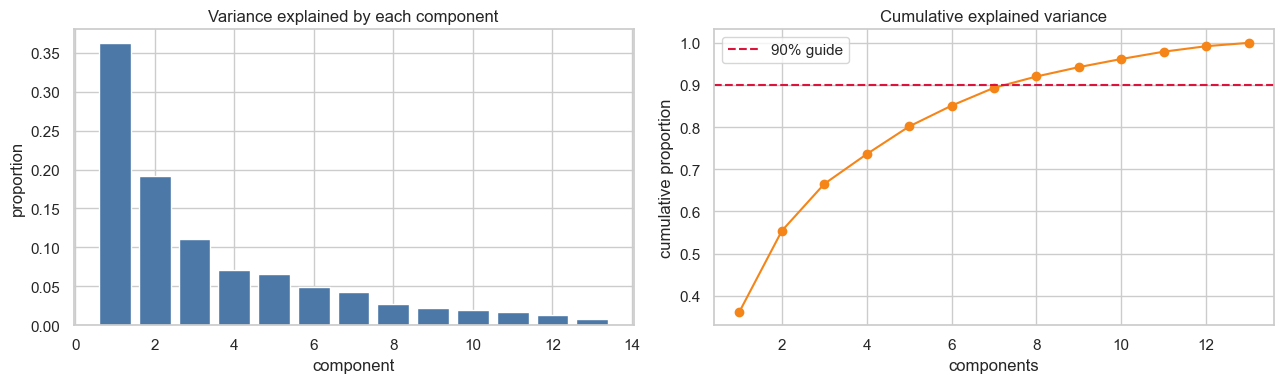

In [3]:
pca = PCA().fit(X_scaled)
cumulative = np.cumsum(pca.explained_variance_ratio_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, len(pca.explained_variance_ratio_)+1), pca.explained_variance_ratio_, color="#4c78a8")
axes[0].set(title="Variance explained by each component", xlabel="component", ylabel="proportion")
axes[1].plot(range(1, len(cumulative)+1), cumulative, marker="o", color="#f58518")
axes[1].axhline(.90, color="crimson", ls="--", label="90% guide")
axes[1].set(title="Cumulative explained variance", xlabel="components", ylabel="cumulative proportion"); axes[1].legend()
plt.tight_layout()
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
display(loadings.sort_values("PC1", key=np.abs, ascending=False).head(8))
print("Components for >=90% variance:", np.argmax(cumulative >= .90) + 1)

## 3. PCA visualization and reconstruction

The scores are the coordinates of each record in the component space. A two-component plot is a projection: nearby points may be similar on the displayed directions but still differ on omitted components. Reconstruction uses a chosen number of components, $\hat Z_m=\sum_{j=1}^{m}\mathrm{PC}_jv_j^T$; discarded components create reconstruction error.

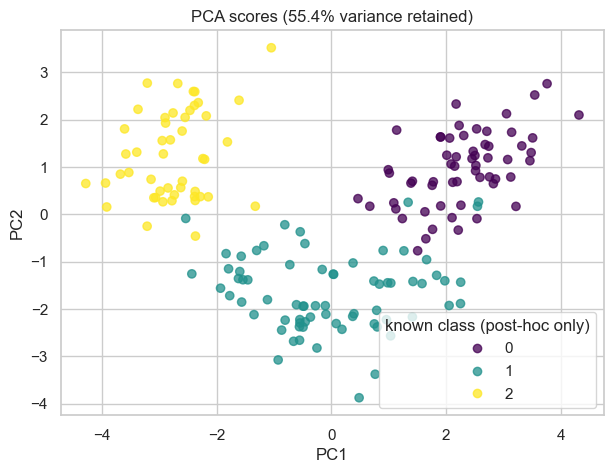

Two-component mean squared reconstruction error: 0.446


In [4]:
pca2 = PCA(n_components=2, random_state=42)
scores = pca2.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(7, 5))
scatter = ax.scatter(scores[:, 0], scores[:, 1], c=species, cmap="viridis", alpha=.75)
ax.set(title=f"PCA scores ({pca2.explained_variance_ratio_.sum():.1%} variance retained)", xlabel="PC1", ylabel="PC2")
ax.legend(*scatter.legend_elements(), title="known class (post-hoc only)"); plt.show()
reconstructed = pca2.inverse_transform(scores)
print(f"Two-component mean squared reconstruction error: {np.mean((X_scaled-reconstructed)**2):.3f}")

## 4. K-means clustering and choosing k

k-means alternates between assigning each record to its nearest centroid and updating centroids to cluster means. It minimizes within-cluster sum of squares:

$$\underset{C_1,\ldots,C_k}{\min}\sum_{r=1}^k\sum_{x_i\in C_r}\lVert x_i-\mu_r\rVert^2.$$

It assumes compact, roughly spherical groups under the selected distance and is sensitive to scale, outliers, initialization, and $k$. Inertia always falls as $k$ grows; use it only with a stability/domain decision. Silhouette compares within-cluster cohesion $a(i)$ and nearest-cluster separation $b(i)$: $s(i)=(b(i)-a(i))/\max(a(i),b(i))$.

Exception in thread Thread-4:
Traceback (most recent call last):
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\threading.py", line 980, in _bootstrap_inner
    self.run()
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\site-packages\ipykernel\ipkernel.py", line 772, in run_closure
    _threading_Thread_run(self)
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\threading.py", line 917, in run
    self._target(*self._args, **self._kwargs)
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\subprocess.py", line 1479, in _readerthread
    buffer.append(fh.read())
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
UnicodeDecodeError: 'charmap' codec can't decode byte 0x8f in position 671: character maps to <undefined>


  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\MP2FW\.pyenv\pyenv-win\versions\3.9.13\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


,k,inertia,silhouette
0,2,1658.759,0.259
1,3,1277.928,0.285
2,4,1175.352,0.259
3,5,1107.007,0.232
4,6,1046.002,0.237
5,7,981.595,0.204
6,8,935.201,0.157


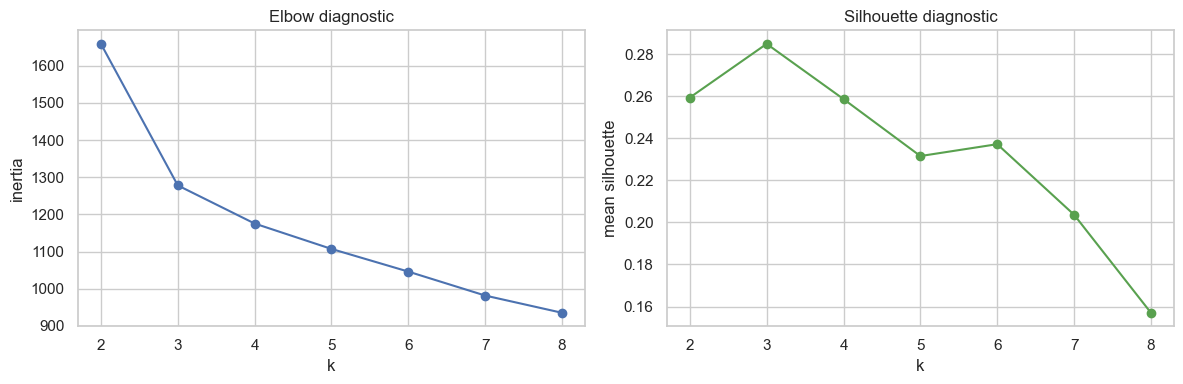

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=30, random_state=42)  # repeated starts reduce local-minimum risk
    labels = model.fit_predict(X_scaled)
    rows.append((k, model.inertia_, silhouette_score(X_scaled, labels)))
selection = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(selection.k, selection.inertia, marker="o"); axes[0].set(title="Elbow diagnostic", xlabel="k", ylabel="inertia")
axes[1].plot(selection.k, selection.silhouette, marker="o", color="#59a14f"); axes[1].set(title="Silhouette diagnostic", xlabel="k", ylabel="mean silhouette")
plt.tight_layout(); display(selection.round(3))

## 5. Cluster profiles and hierarchical clustering

Cluster labels have no intrinsic meaning: profile groups in original units before naming them. Hierarchical agglomerative clustering starts with single-record clusters and merges them according to a linkage rule. Ward linkage chooses merges with small increases in within-cluster variance; complete linkage uses the farthest pair, and single linkage can chain nearby points. A dendrogram shows every merge, but selecting a horizontal cut still needs judgment.

cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


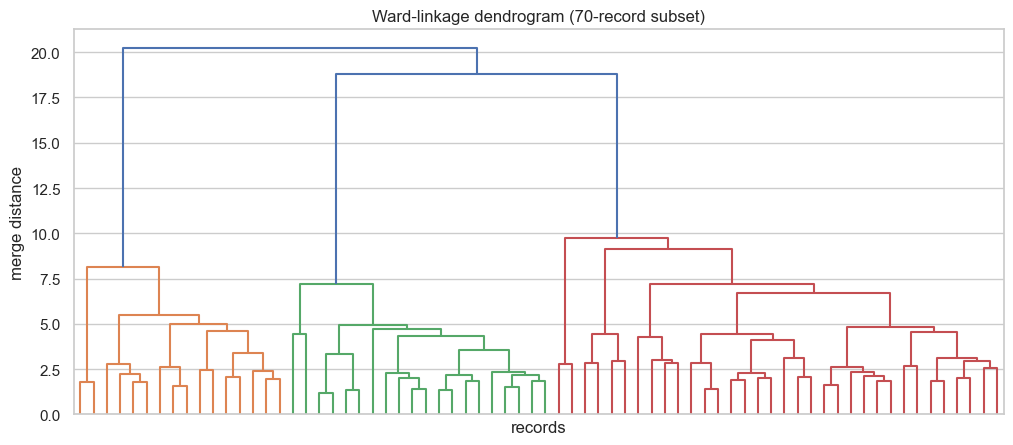

Agreement between k-means and hierarchical labels is not expected to be exact.


hierarchical,0,1,2
k-means,,,
0,57,5,3
1,0,51,0
2,1,0,61


In [6]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

kmeans3 = KMeans(n_clusters=3, n_init=30, random_state=42)
cluster = kmeans3.fit_predict(X_scaled)
profile = X.assign(cluster=cluster).groupby("cluster").mean().T
display(profile.round(2))

# A random subset keeps the dendrogram readable; use the full data for the final labels.
subset = X_scaled[rng.choice(len(X_scaled), 70, replace=False)]
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(linkage(subset, method="ward"), no_labels=True, color_threshold=None, ax=ax)
ax.set(title="Ward-linkage dendrogram (70-record subset)", xlabel="records", ylabel="merge distance"); plt.show()
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X_scaled)
print("Agreement between k-means and hierarchical labels is not expected to be exact.")
pd.crosstab(cluster, hierarchical, rownames=["k-means"], colnames=["hierarchical"])

## Summary and key takeaways

- Unsupervised outputs are hypotheses about structure; validate with domain knowledge, stability, and alternative feature choices.
- Scale features before PCA or Euclidean-distance clustering unless original units deliberately encode importance.
- PCA preserves variance, not necessarily interpretability or prediction; inspect loadings and reconstruction trade-offs.
- k-means requires a chosen k and works best for compact clusters; use multiple starts and avoid treating an elbow as proof.
- Dendrograms are useful for exploring hierarchy, but linkage method and cut height change the result. Always profile clusters before assigning labels.

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 7. Concepts are informed by the supplied PDF; all explanations and code in this notebook are original.